In [1]:
# This Python 3 environment comes with many helpful analytics libraries installed
# It is defined by the kaggle/python Docker image: https://github.com/kaggle/docker-python
# For example, here's several helpful packages to load

import numpy as np # linear algebra
import pandas as pd # data processing, CSV file I/O (e.g. pd.read_csv)

# Input data files are available in the read-only "../input/" directory
# For example, running this (by clicking run or pressing Shift+Enter) will list all files under the input directory

import os
for dirname, _, filenames in os.walk('/kaggle/input'):
    for filename in filenames:
        print(os.path.join(dirname, filename))

# You can write up to 20GB to the current directory (/kaggle/working/) that gets preserved as output when you create a version using "Save & Run All" 
# You can also write temporary files to /kaggle/temp/, but they won't be saved outside of the current session

/kaggle/input/playground-series-s5e7/sample_submission.csv
/kaggle/input/playground-series-s5e7/train.csv
/kaggle/input/playground-series-s5e7/test.csv


In [2]:
!pip install -U scikit-learn imbalanced-learn

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 13.5/13.5 MB 90.0 MB/s eta 0:00:00
  Attempting uninstall: scikit-learn
    Found existing installation: scikit-learn 1.2.2
    Uninstalling scikit-learn-1.2.2:
      Successfully uninstalled scikit-learn-1.2.2
ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
category-encoders 2.7.0 requires scikit-learn<1.6.0,>=1.0.0, but you have scikit-learn 1.6.1 which is incompatible.
cesium 0.12.4 requires numpy<3.0,>=2.0, but you have numpy 1.26.4 which is incompatible.


In [3]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import warnings
from sklearn.model_selection import StratifiedKFold
from sklearn.preprocessing import LabelEncoder, StandardScaler, OneHotEncoder
from sklearn.impute import SimpleImputer
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix
from sklearn.linear_model import LogisticRegression
from imblearn.pipeline import Pipeline as ImbPipeline
from imblearn.over_sampling import SMOTE
import lightgbm as lgb
import xgboost as xgb
warnings.filterwarnings('ignore')
sns.set_style('whitegrid')
pd.set_option('display.max_columns', None)

print("Setup Complete. Libraries imported successfully.")

Setup Complete. Libraries imported successfully.


In [4]:
try:
    train_df = pd.read_csv("/kaggle/input/playground-series-s5e7/train.csv")
    test_df = pd.read_csv("/kaggle/input/playground-series-s5e7/test.csv")
    sample_submission_df = pd.read_csv("/kaggle/input/playground-series-s5e7/sample_submission.csv")
except FileNotFoundError:
    print("Kaggle directory not found. Please adjust file paths if running locally.")

In [5]:
print("Shape of training data:", train_df.shape)
print("Shape of testing data:", test_df.shape)

Shape of training data: (18524, 9)
Shape of testing data: (6175, 8)


In [6]:
print("\nTraining Data Head:")
display(train_df.head())


Training Data Head:


,id,Time_spent_Alone,Stage_fear,Social_event_attendance,Going_outside,Drained_after_socializing,Friends_circle_size,Post_frequency,Personality
0,0,0.0,No,6.0,4.0,No,15.0,5.0,Extrovert
1,1,1.0,No,7.0,3.0,No,10.0,8.0,Extrovert
2,2,6.0,Yes,1.0,0.0,NaN,3.0,0.0,Introvert
3,3,3.0,No,7.0,3.0,No,11.0,5.0,Extrovert
4,4,1.0,No,4.0,4.0,No,13.0,NaN,Extrovert


In [7]:
print("--- Data Summary ---")
train_df.info()

--- Data Summary ---
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 18524 entries, 0 to 18523
Data columns (total 9 columns):
 #   Column                     Non-Null Count  Dtype  
---  ------                     --------------  -----  
 0   id                         18524 non-null  int64  
 1   Time_spent_Alone           17334 non-null  float64
 2   Stage_fear                 16631 non-null  object 
 3   Social_event_attendance    17344 non-null  float64
 4   Going_outside              17058 non-null  float64
 5   Drained_after_socializing  17375 non-null  object 
 6   Friends_circle_size        17470 non-null  float64
 7   Post_frequency             17260 non-null  float64
 8   Personality                18524 non-null  object 
dtypes: float64(5), int64(1), object(3)
memory usage: 1.3+ MB


In [8]:
print("\n--- Missing Values ---")
print("Training set missing values:\n", train_df.isnull().sum())
print("\nTest set missing values:\n", test_df.isnull().sum())


--- Missing Values ---
Training set missing values:
 id                              0
Time_spent_Alone             1190
Stage_fear                   1893
Social_event_attendance      1180
Going_outside                1466
Drained_after_socializing    1149
Friends_circle_size          1054
Post_frequency               1264
Personality                     0
dtype: int64

Test set missing values:
 id                             0
Time_spent_Alone             425
Stage_fear                   598
Social_event_attendance      397
Going_outside                466
Drained_after_socializing    432
Friends_circle_size          350
Post_frequency               408
dtype: int64


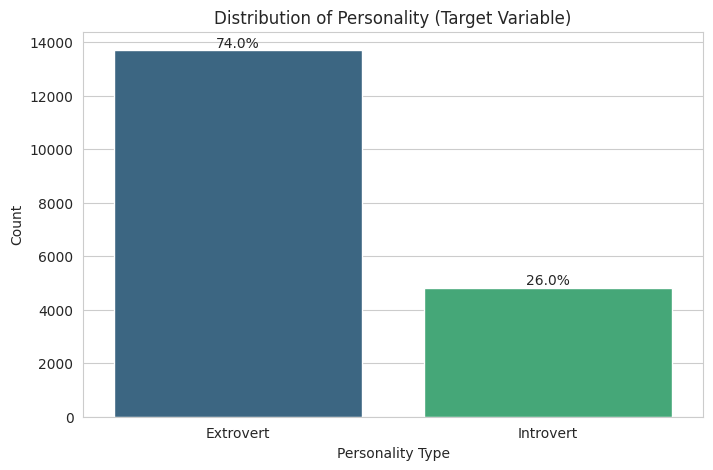

Class imbalance confirmed. SMOTE is a suitable strategy.


In [9]:
plt.figure(figsize=(8, 5))
ax = sns.countplot(x='Personality', data=train_df, palette='viridis')
plt.title('Distribution of Personality (Target Variable)')
plt.ylabel('Count')
plt.xlabel('Personality Type')
# Add percentage labels
total = len(train_df)
for p in ax.patches:
    percentage = f'{100 * p.get_height() / total:.1f}%'
    x = p.get_x() + p.get_width() / 2
    y = p.get_height()
    ax.annotate(percentage, (x, y), ha='center', va='bottom')
plt.show()
print("Class imbalance confirmed. SMOTE is a suitable strategy.")

In [10]:
numerical_features = train_df.select_dtypes(include=np.number).columns.tolist()
numerical_features.remove('id')


--- Numerical Feature Distributions by Personality ---


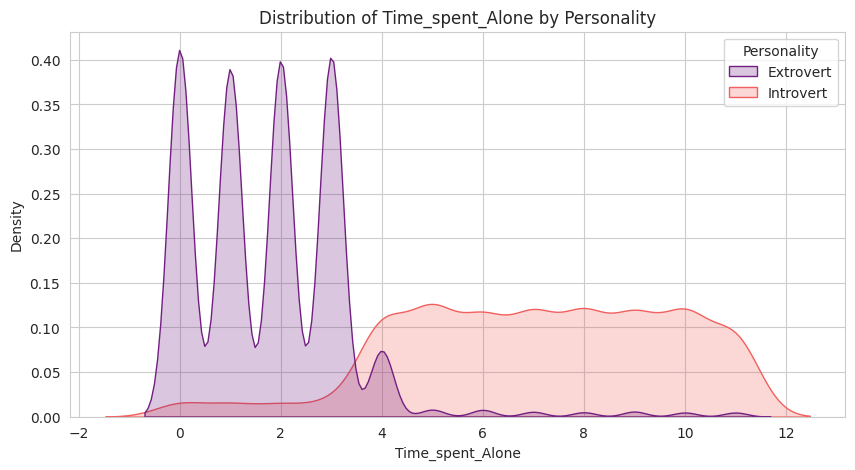

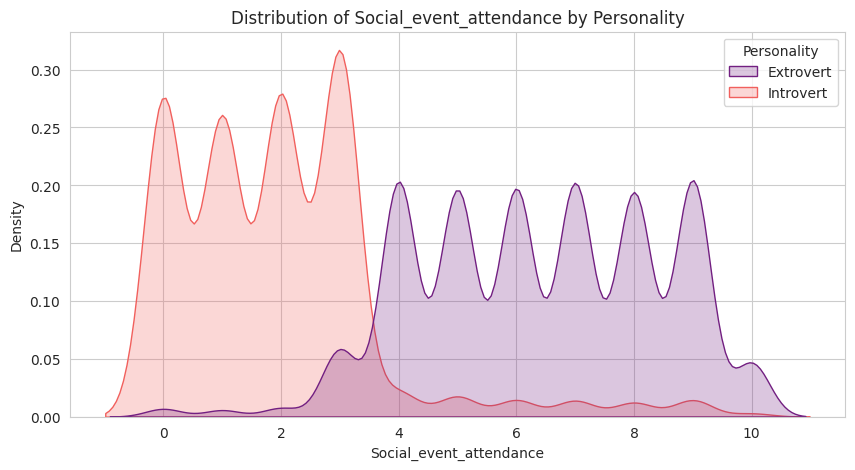

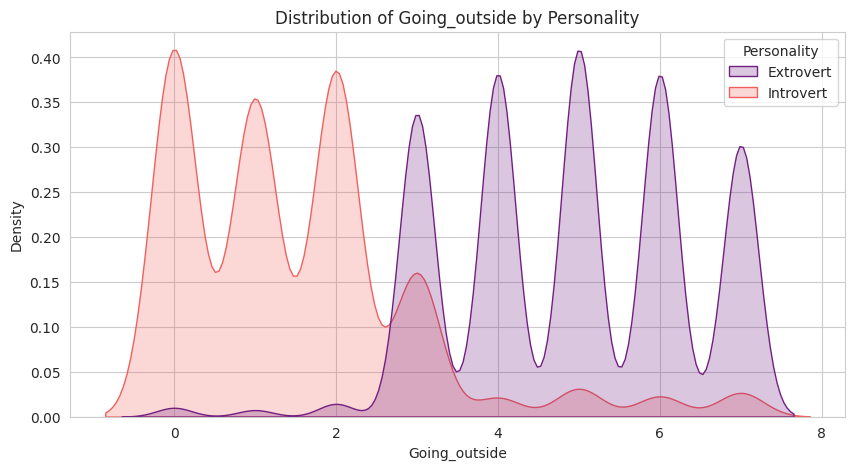

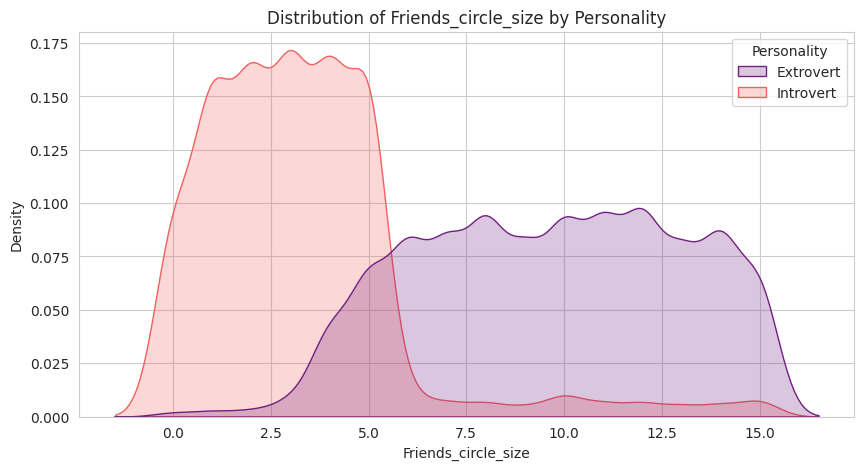

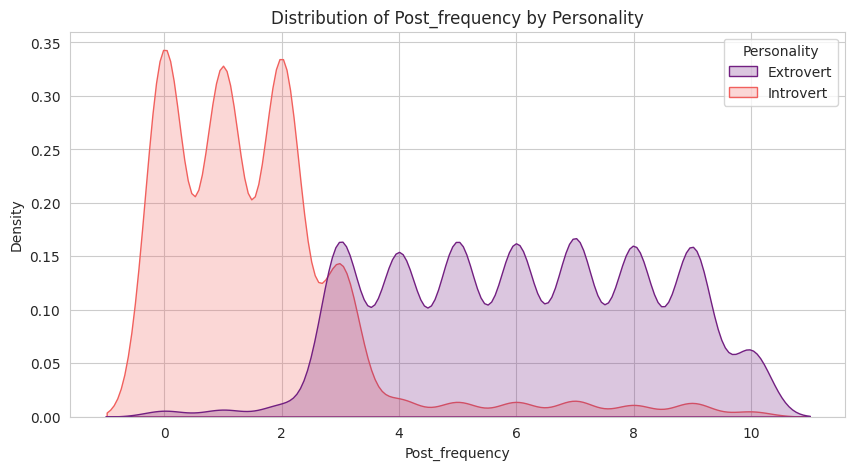

In [11]:
print("\n--- Numerical Feature Distributions by Personality ---")
for col in numerical_features:
    plt.figure(figsize=(10, 5))
    # CORRECTED LINE: Use the 'data', 'x', and 'hue' parameters
    sns.kdeplot(data=train_df, x=col, hue='Personality', fill=True, palette='magma', common_norm=False)
    plt.title(f'Distribution of {col} by Personality')
    plt.show()

In [12]:
categorical_features = ['Stage_fear', 'Drained_after_socializing']


--- Categorical Feature Distributions by Personality ---


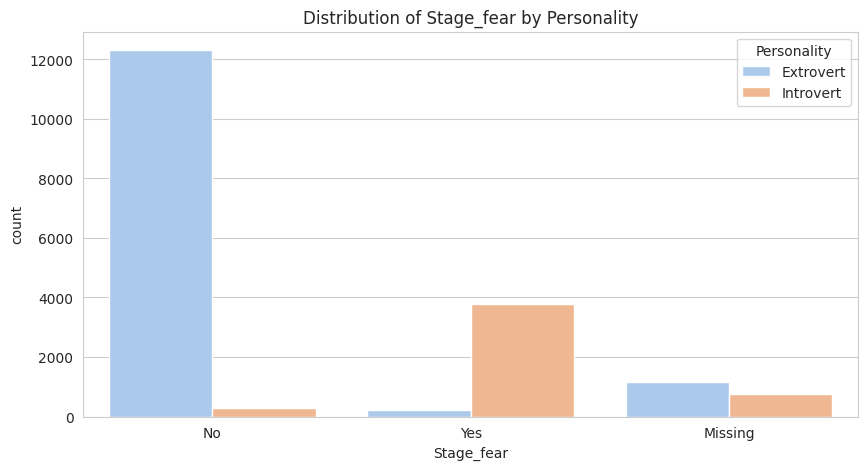

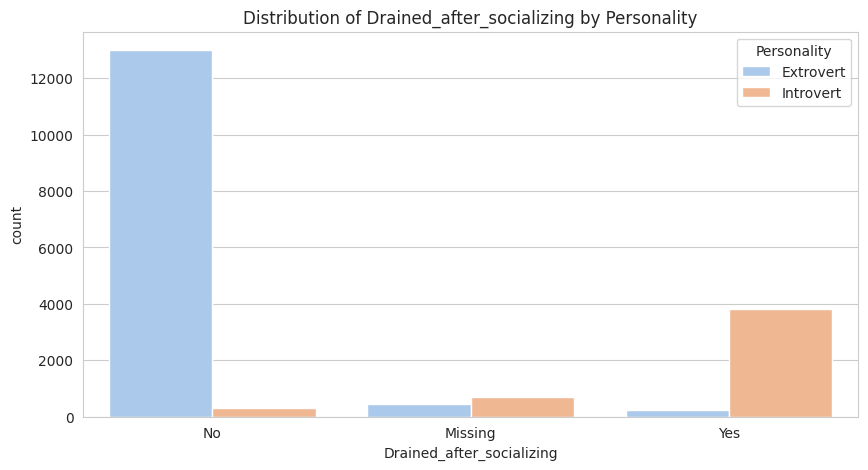

In [13]:
print("\n--- Categorical Feature Distributions by Personality ---")
for col in categorical_features:
    # Fill NaN to visualize them as a separate category
    temp_df = train_df.copy()
    temp_df[col] = temp_df[col].fillna('Missing')
    
    plt.figure(figsize=(10, 5))
    sns.countplot(x=col, hue='Personality', data=temp_df, palette='pastel')
    plt.title(f'Distribution of {col} by Personality')
    plt.show()

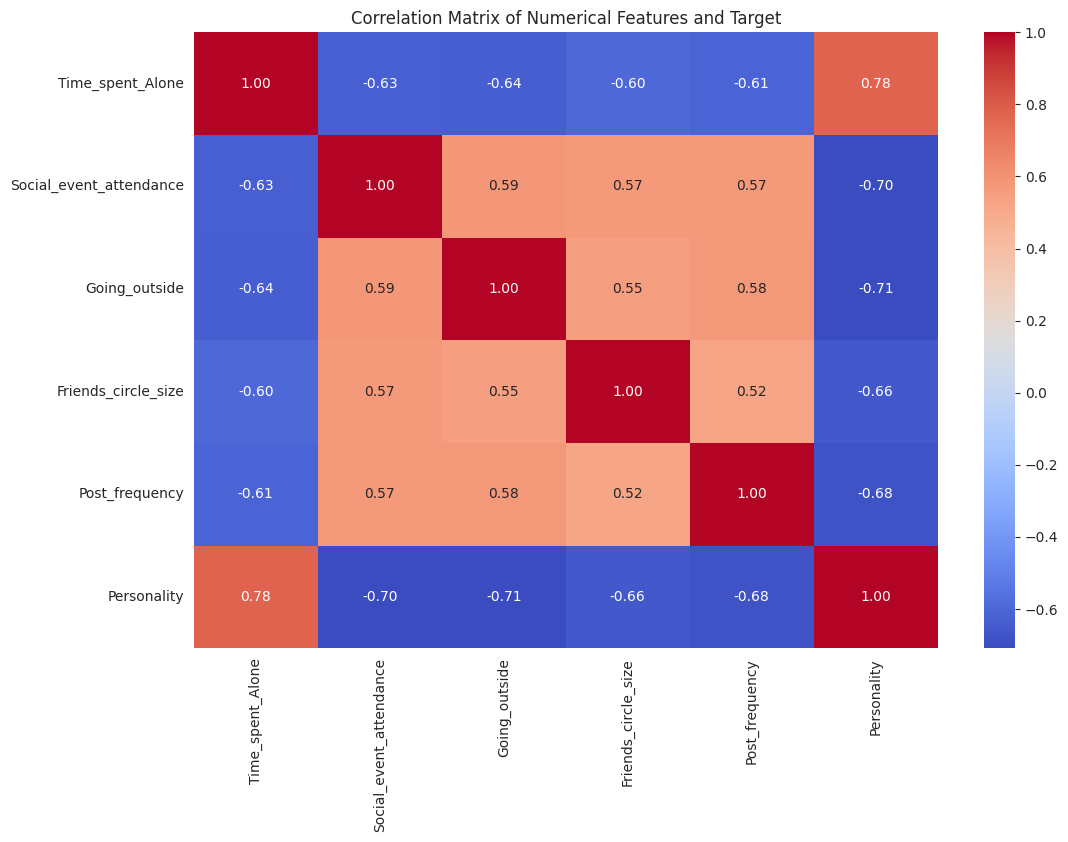

In [14]:
plt.figure(figsize=(12, 8))
# We will encode the target to include it in the correlation matrix
temp_corr_df = train_df.copy()
temp_corr_df['Personality'] = LabelEncoder().fit_transform(temp_corr_df['Personality'])
sns.heatmap(temp_corr_df[numerical_features + ['Personality']].corr(), annot=True, cmap='coolwarm', fmt='.2f')
plt.title('Correlation Matrix of Numerical Features and Target')
plt.show()

In [15]:
X = train_df.drop('Personality', axis=1)
y = train_df['Personality']

In [16]:
X = X.drop('id', axis=1)
test_ids = test_df['id']
X_test = test_df.drop('id', axis=1)

In [17]:
le = LabelEncoder()
y_encoded = le.fit_transform(y)

In [18]:
numerical_features = X.select_dtypes(include=np.number).columns.tolist()
categorical_features = X.select_dtypes(include=['object', 'bool']).columns.tolist()

In [19]:
print("Numerical Features:", numerical_features)
print("Categorical Features:", categorical_features)

Numerical Features: ['Time_spent_Alone', 'Social_event_attendance', 'Going_outside', 'Friends_circle_size', 'Post_frequency']
Categorical Features: ['Stage_fear', 'Drained_after_socializing']


In [20]:
numerical_transformer = Pipeline(steps=[
    ('imputer', SimpleImputer(strategy='median')),
    ('scaler', StandardScaler())
])

In [21]:
categorical_transformer = Pipeline(steps=[
    ('imputer', SimpleImputer(strategy='most_frequent')),
    ('onehot', OneHotEncoder(handle_unknown='ignore', drop='first')) # drop='first' to avoid multicollinearity
])

In [22]:
preprocessor = ColumnTransformer(
    transformers=[
        ('num', numerical_transformer, numerical_features),
        ('cat', categorical_transformer, categorical_features)
    ],
    remainder='passthrough' # Keep other columns (if any)
)

In [23]:
from sklearn.base import BaseEstimator, ClassifierMixin
import xgboost as xgb

class XGBoostClassifier(BaseEstimator, ClassifierMixin):
    def __init__(self, **kwargs):
        self.estimator = xgb.XGBClassifier(**kwargs)

    def fit(self, X, y=None, **fit_params):
        self.estimator.fit(X, y, **fit_params)
        return self

    def predict(self, X):
        return self.estimator.predict(X)

    def predict_proba(self, X):
        return self.estimator.predict_proba(X)

In [24]:
models = {
    'LogisticRegression': LogisticRegression(random_state=42, solver='liblinear', C=0.5), # Added some regularization

    'LightGBM': lgb.LGBMClassifier(
        random_state=42,
        objective='binary',
        metric='binary_logloss',
        n_estimators=2000,
        learning_rate=0.02,
        num_leaves=20,
        max_depth=7,
        reg_alpha=0.1,
        reg_lambda=0.1,
        colsample_bytree=0.8,
        subsample=0.8,
        boosting_type='gbdt'
    ),

    'XGBoost': XGBoostClassifier( # Using our wrapper
        random_state=42,
        objective='binary:logistic',
        eval_metric='logloss',
        n_estimators=2000,
        learning_rate=0.02,
        max_depth=5,
        subsample=0.8,
        colsample_bytree=0.8,
        gamma=0.1,
        use_label_encoder=False
    )
}

In [25]:
N_SPLITS = 10
skf = StratifiedKFold(n_splits=N_SPLITS, shuffle=True, random_state=42)

# Dictionaries to store predictions from each model
oof_preds = {}
test_preds = {}
model_scores = {}

print(f"\n--- Starting Training for {len(models)} models with {N_SPLITS}-Fold CV & SMOTE ---")

# --- 4.3. Training Loop ---
for name, model in models.items():
    print(f"\n===== Training {name} =====")

    # Create the special imblearn pipeline
    # This correctly applies SMOTE only to the training data in each fold
    pipeline = ImbPipeline(steps=[
        ('preprocessor', preprocessor),
        ('smote', SMOTE(random_state=42)),
        ('classifier', model)
    ])

    # Arrays to store predictions for this model
    current_oof_preds = np.zeros(len(X))
    current_test_preds = np.zeros(len(X_test))

    for fold, (train_idx, val_idx) in enumerate(skf.split(X, y_encoded)):
        X_train, X_val = X.iloc[train_idx], X.iloc[val_idx]
        y_train, y_val = y_encoded[train_idx], y_encoded[val_idx]

        # Fit the pipeline on the training data for this fold
        pipeline.fit(X_train, y_train)

        # Predict probabilities for the validation set (for soft voting)
        val_preds_proba = pipeline.predict_proba(X_val)[:, 1]
        current_oof_preds[val_idx] = val_preds_proba

        # Predict probabilities for the test set and average them across folds
        current_test_preds += pipeline.predict_proba(X_test)[:, 1] / N_SPLITS

    # Store the results for this model
    oof_preds[name] = current_oof_preds
    test_preds[name] = current_test_preds
    
    # Evaluate OOF predictions for this individual model
    accuracy = accuracy_score(y_encoded, (current_oof_preds > 0.5).astype(int))
    model_scores[name] = accuracy
    print(f"--- {name} OOF Accuracy: {accuracy:.6f} ---")

print("\n--- Individual Model Performance Summary ---")
for name, score in model_scores.items():
    print(f"{name}: {score:.6f}")


--- Starting Training for 3 models with 10-Fold CV & SMOTE ---

===== Training LogisticRegression =====
--- LogisticRegression OOF Accuracy: 0.968797 ---

===== Training LightGBM =====
[LightGBM] [Info] Number of positive: 12329, number of negative: 12329
[LightGBM] [Info] Auto-choosing col-wise multi-threading, the overhead of testing was 0.003021 seconds.
You can set `force_col_wise=true` to remove the overhead.
[LightGBM] [Info] Total Bins 1299
[LightGBM] [Info] Number of data points in the train set: 24658, number of used features: 7
[LightGBM] [Info] [binary:BoostFromScore]: pavg=0.500000 -> initscore=0.000000
[LightGBM] [Info] Number of positive: 12329, number of negative: 12329
[LightGBM] [Info] Auto-choosing col-wise multi-threading, the overhead of testing was 0.001593 seconds.
You can set `force_col_wise=true` to remove the overhead.
[LightGBM] [Info] Total Bins 1295
[LightGBM] [Info] Number of data points in the train set: 24658, number of used features: 7
[LightGBM] [Info]

In [26]:
oof_df = pd.DataFrame(oof_preds)
# Calculate the average probability (soft voting)
ensemble_oof_preds = oof_df.mean(axis=1)

# Evaluate the ensembled OOF predictions
ensemble_accuracy = accuracy_score(y_encoded, (ensemble_oof_preds > 0.5).astype(int))

print("\n--- Ensemble Performance ---")
print(f"Ensemble OOF Accuracy: {ensemble_accuracy:.6f}")

print("\nEnsemble OOF Classification Report:")
print(classification_report(y_encoded, (ensemble_oof_preds > 0.5).astype(int), target_names=le.classes_))


--- Ensemble Performance ---
Ensemble OOF Accuracy: 0.968689

Ensemble OOF Classification Report:
              precision    recall  f1-score   support

   Extrovert       0.98      0.98      0.98     13699
   Introvert       0.94      0.94      0.94      4825

    accuracy                           0.97     18524
   macro avg       0.96      0.96      0.96     18524
weighted avg       0.97      0.97      0.97     18524



In [27]:
test_df_preds = pd.DataFrame(test_preds)
# Calculate the average probability for the test set
ensemble_test_preds_proba = test_df_preds.mean(axis=1)

In [28]:
final_test_preds_encoded = (ensemble_test_preds_proba > 0.5).astype(int)

In [29]:
final_test_preds = le.inverse_transform(final_test_preds_encoded)

In [30]:
submission_df = pd.DataFrame({
    'id': test_ids,
    'Personality': final_test_preds
})

In [31]:
submission_df.to_csv('ensemble_smote_submission.csv', index=False)

In [32]:
print("\n--- Submission File Created ---")
print("Submission file 'ensemble_smote_submission.csv' has been generated.")
display(submission_df.head())


--- Submission File Created ---
Submission file 'ensemble_smote_submission.csv' has been generated.


,id,Personality
0,18524,Extrovert
1,18525,Introvert
2,18526,Extrovert
3,18527,Extrovert
4,18528,Introvert
